# Lab 3 — Canny Edge Detector
**Flow:** ảnh → grayscale → Gaussian → gradient → NMS → ngưỡng kép → hysteresis → bản đồ cạnh → phân tích vùng/hình dạng.
Chạy **Run All** bằng kernel đã cài `requirements.txt`. Notebook giải cả lý thuyết và thực hành; xem README để đọc giới hạn đánh giá.

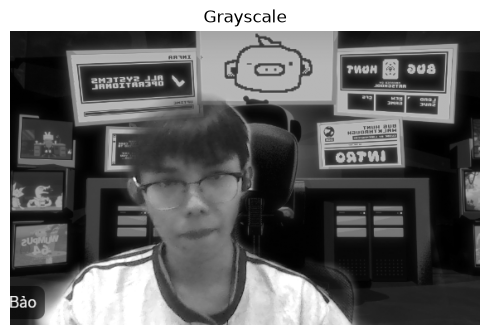

Kích thước thí nghiệm: (355, 567)


In [1]:
from pathlib import Path
import sys, json
import numpy as np
import cv2
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Markdown
from skimage.feature import canny
%matplotlib inline
LAB=Path.cwd().resolve()
if not (LAB/'canny_lab.py').exists(): LAB=LAB/'Lab_3'
if not (LAB/'canny_lab.py').exists(): raise FileNotFoundError('Mở từ Lab_3 hoặc thư mục gốc repo')
sys.path.insert(0,str(LAB))
from canny_lab import *
OUT=LAB/'outputs'; OUT.mkdir(exist_ok=True)
gray=read_gray(LAB/'images/sample.jpg')
# Giới hạn chiều dài lớn nhất để các thí nghiệm chạy nhanh.
scale=min(1,640/max(gray.shape))
if scale<1: gray=cv2.resize(gray,None,fx=scale,fy=scale,interpolation=cv2.INTER_AREA)
def show(items,columns=3,filename=None):
    fig,axes=plt.subplots((len(items)+columns-1)//columns,columns,figsize=(5*columns,3.8*((len(items)+columns-1)//columns)),squeeze=False)
    for ax,(title,values) in zip(axes.ravel(),items):
        ax.imshow(values,cmap='gray'); ax.set_title(title); ax.axis('off')
    for ax in axes.ravel()[len(items):]: ax.axis('off')
    plt.tight_layout()
    if filename: fig.savefig(OUT/filename,dpi=130)
    plt.show()
show([('Grayscale',gray)],columns=1)
print('Kích thước thí nghiệm:',gray.shape)

## 1. Giảm nhiễu, gradient, NMS, ngưỡng kép và theo dõi cạnh
Gaussian làm mượt trước đạo hàm. Sobel tính Gx, Gy; độ lớn gradient là $\sqrt{G_x^2+G_y^2}$. NMS so sánh hai lân cận theo hướng gradient để làm mảnh cạnh. Bản giáo dục dùng bốn hướng lượng tử hóa.
Cạnh mạnh: >= high. Cạnh yếu: low <= giá trị < high. Hysteresis giữ mọi cạnh yếu nối với cạnh mạnh qua đường đi 8 hướng; loại các thành phần không có cạnh mạnh.

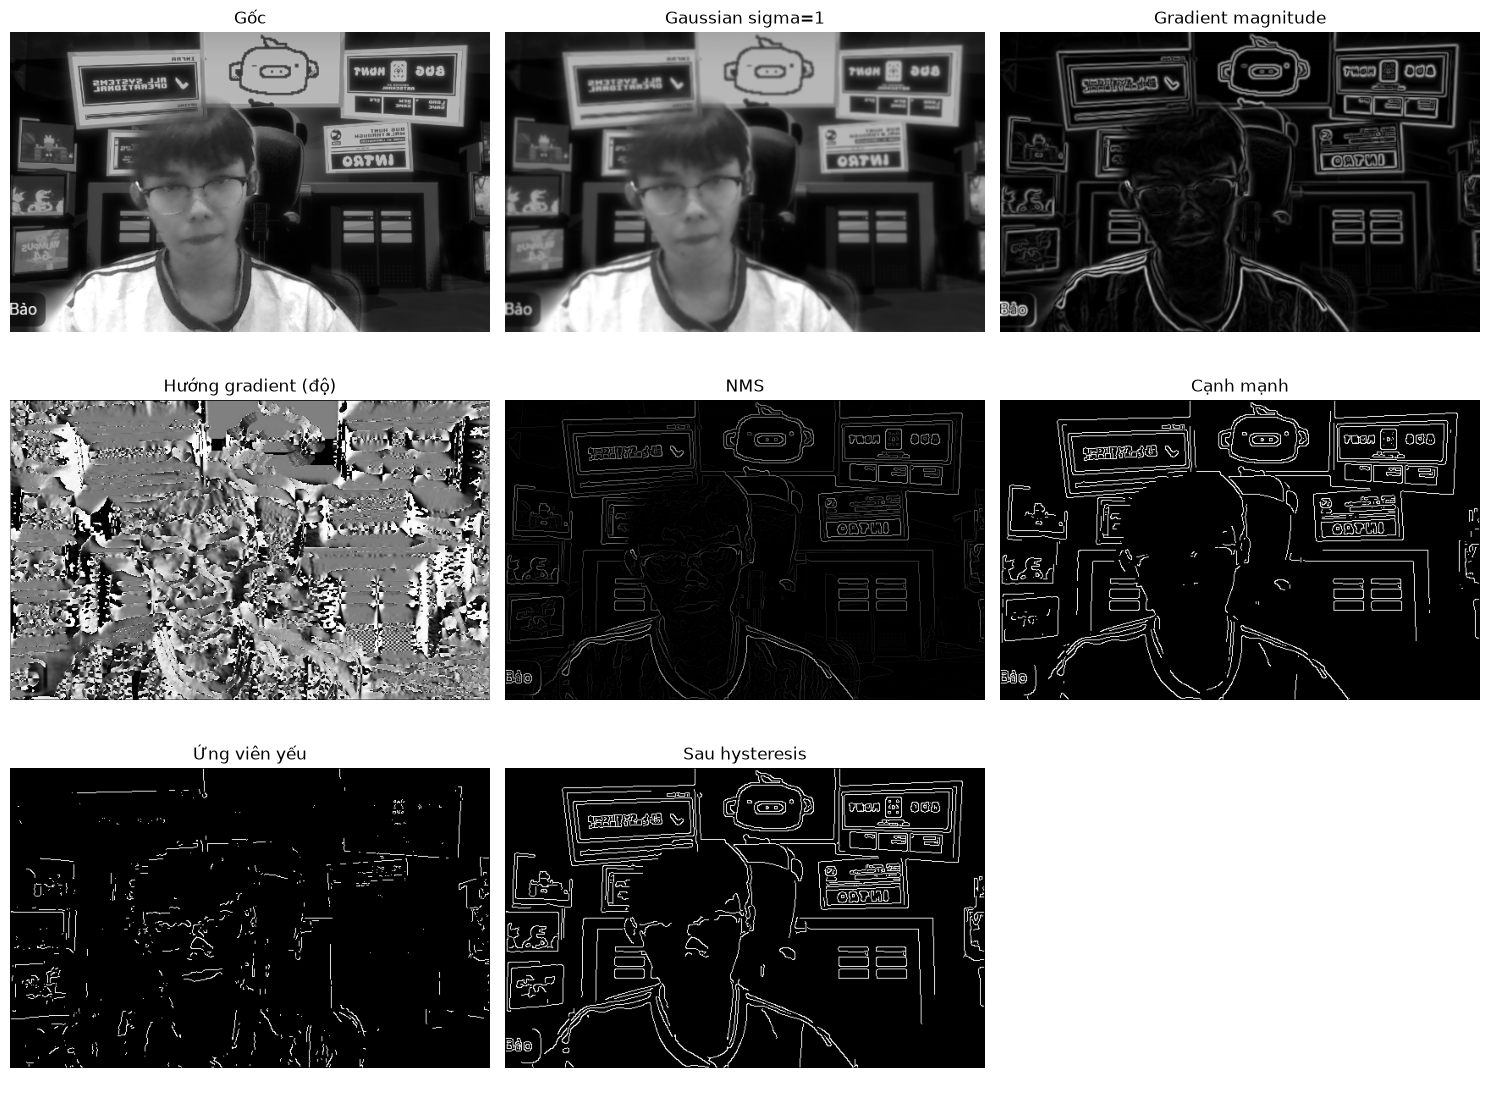

Mỗi panel tự chuẩn hóa mức hiển thị; magnitude là đơn vị gradient, không phải mức xám 0–255.


In [2]:
stages=manual_canny(gray,sigma=1,low=50,high=100)
show([('Gốc',gray),('Gaussian sigma=1',stages['blurred']),('Gradient magnitude',stages['magnitude']),
      ('Hướng gradient (độ)',stages['angle']),('NMS',stages['nms']),('Cạnh mạnh',stages['strong']),
      ('Ứng viên yếu',stages['weak']),('Sau hysteresis',stages['edges'])],filename='01_stages.png')
print('Mỗi panel tự chuẩn hóa mức hiển thị; magnitude là đơn vị gradient, không phải mức xám 0–255.')

## 2. OpenCV và scikit-image
Baseline project: sigma=1, low=50, high=100, OpenCV L2gradient=True. scikit-image nhận ảnh [0,1] nên chia ngưỡng cho 255. Kết quả không nhất thiết giống nhau do đạo hàm, NMS, xử lý biên và làm tròn khác nhau.
**OpenCV không có ngưỡng mặc định**: phải cung cấp threshold1/threshold2. scikit-image có mặc định sigma=1, low=0.1, high=0.2 với use_quantiles=False; hiển thị riêng dưới đây.

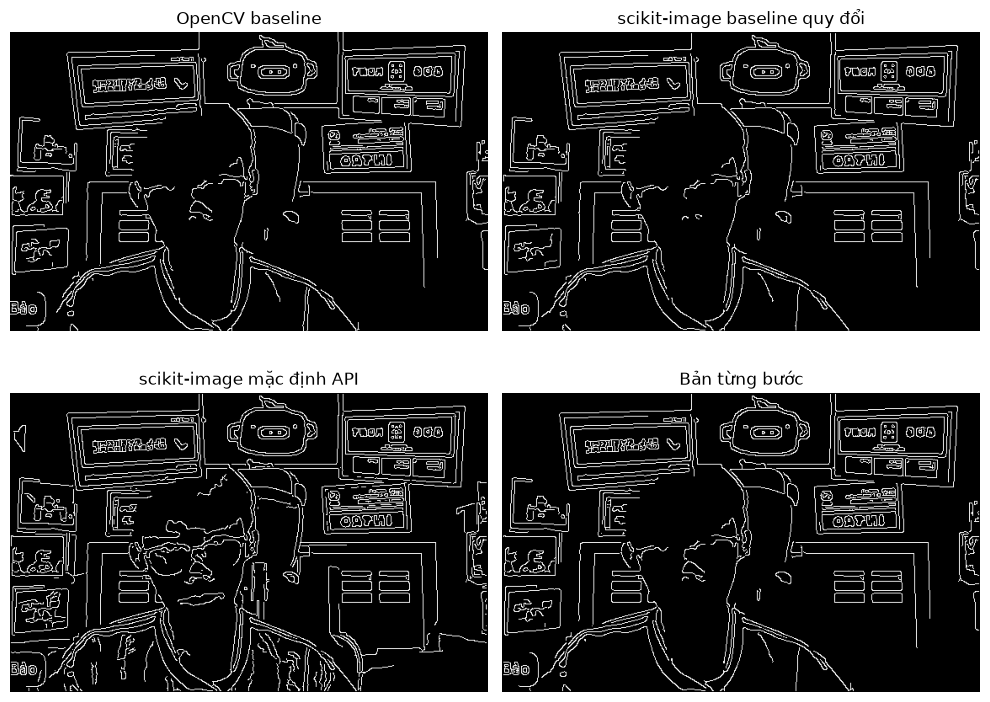

In [3]:
show([('OpenCV baseline',opencv_canny(gray)),('scikit-image baseline quy đổi',skimage_canny(gray)),
      ('scikit-image mặc định API',canny(gray.astype(float)/255)),('Bản từng bước',stages['edges'])],columns=2,filename='02_libraries.png')

## 3. Khảo sát sigma và ngưỡng
Mỗi hàng là một sigma; mỗi cột là cặp low/high. Số pixel cạnh giúp quan sát mật độ nhưng không đo chất lượng. Sigma cao có thể mất chi tiết; ngưỡng thấp có thể tăng nhiễu, ngưỡng cao mất cạnh yếu.

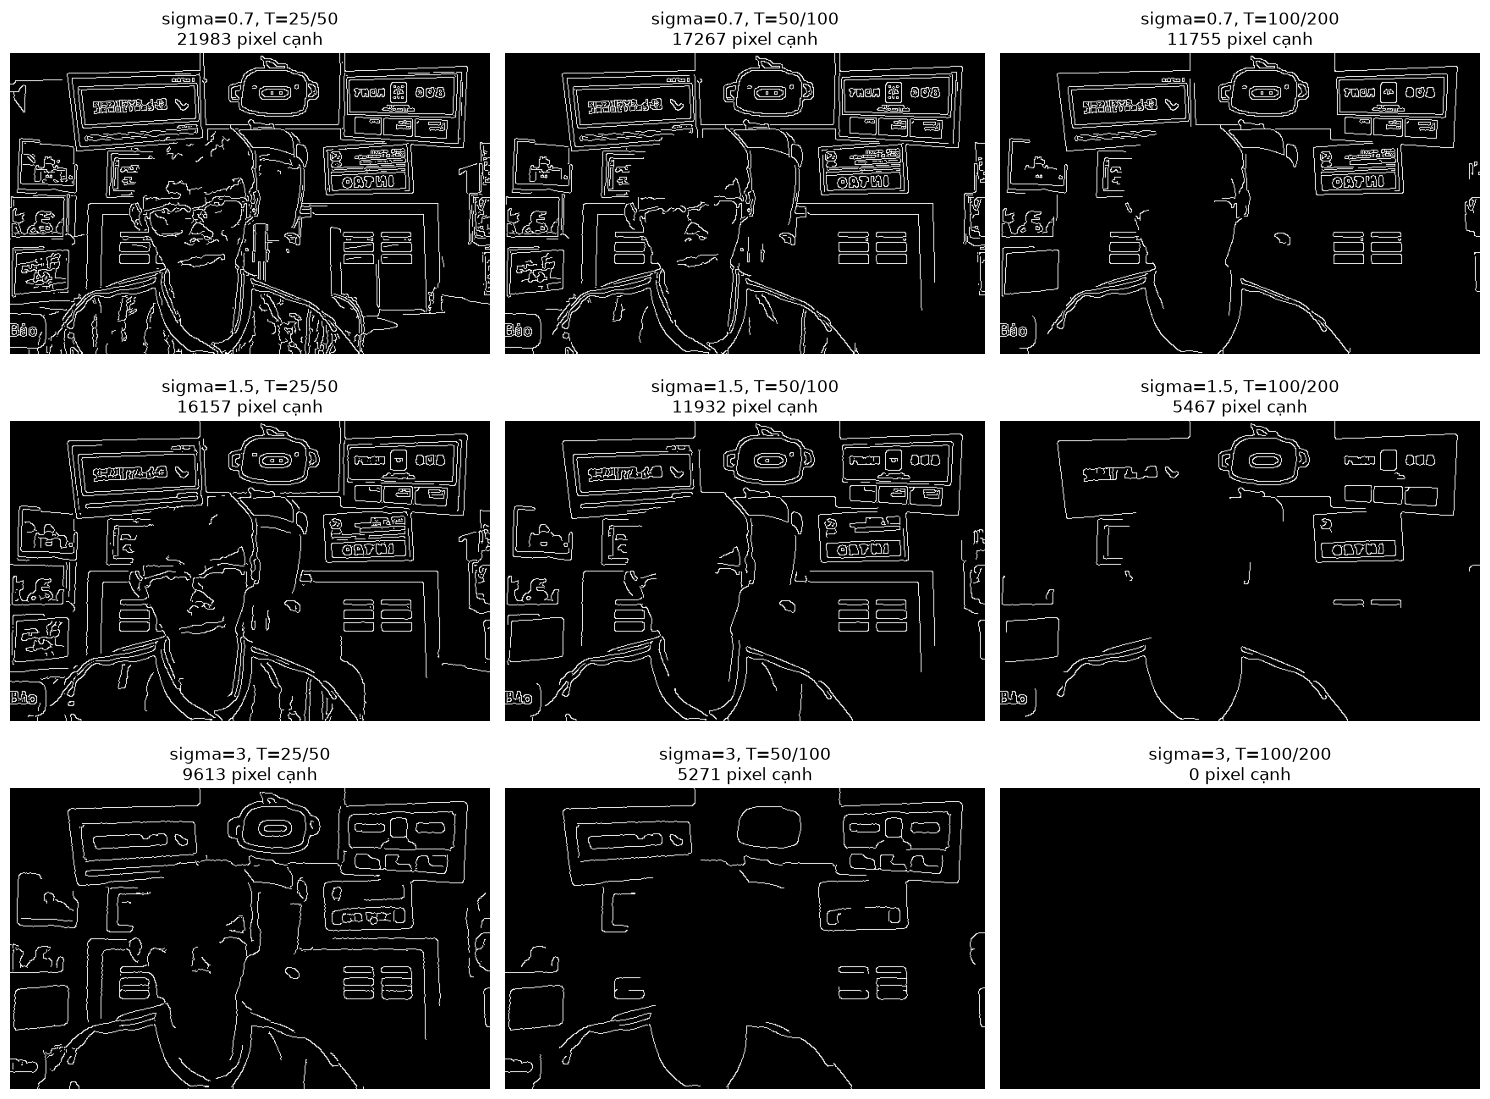

In [4]:
items=[]
for sigma in (0.7,1.5,3):
    for low,high in ((25,50),(50,100),(100,200)):
        edges=opencv_canny(gray,sigma,low,high)
        items.append((f'sigma={sigma}, T={low}/{high}\n{edges.sum()} pixel cạnh',edges))
show(items,filename='03_parameters.png')

## 4. Ảnh nhiễu, tương phản thấp, nhiều chi tiết
Ảnh nhiều chi tiết là ảnh mẫu gốc. Sinh nhiễu Gaussian seed 42 và tạo bản ít tương phản bằng 0.25*f+90. Các cấu hình dưới là minh họa; không được xem là tham số tối ưu trên mọi ảnh.

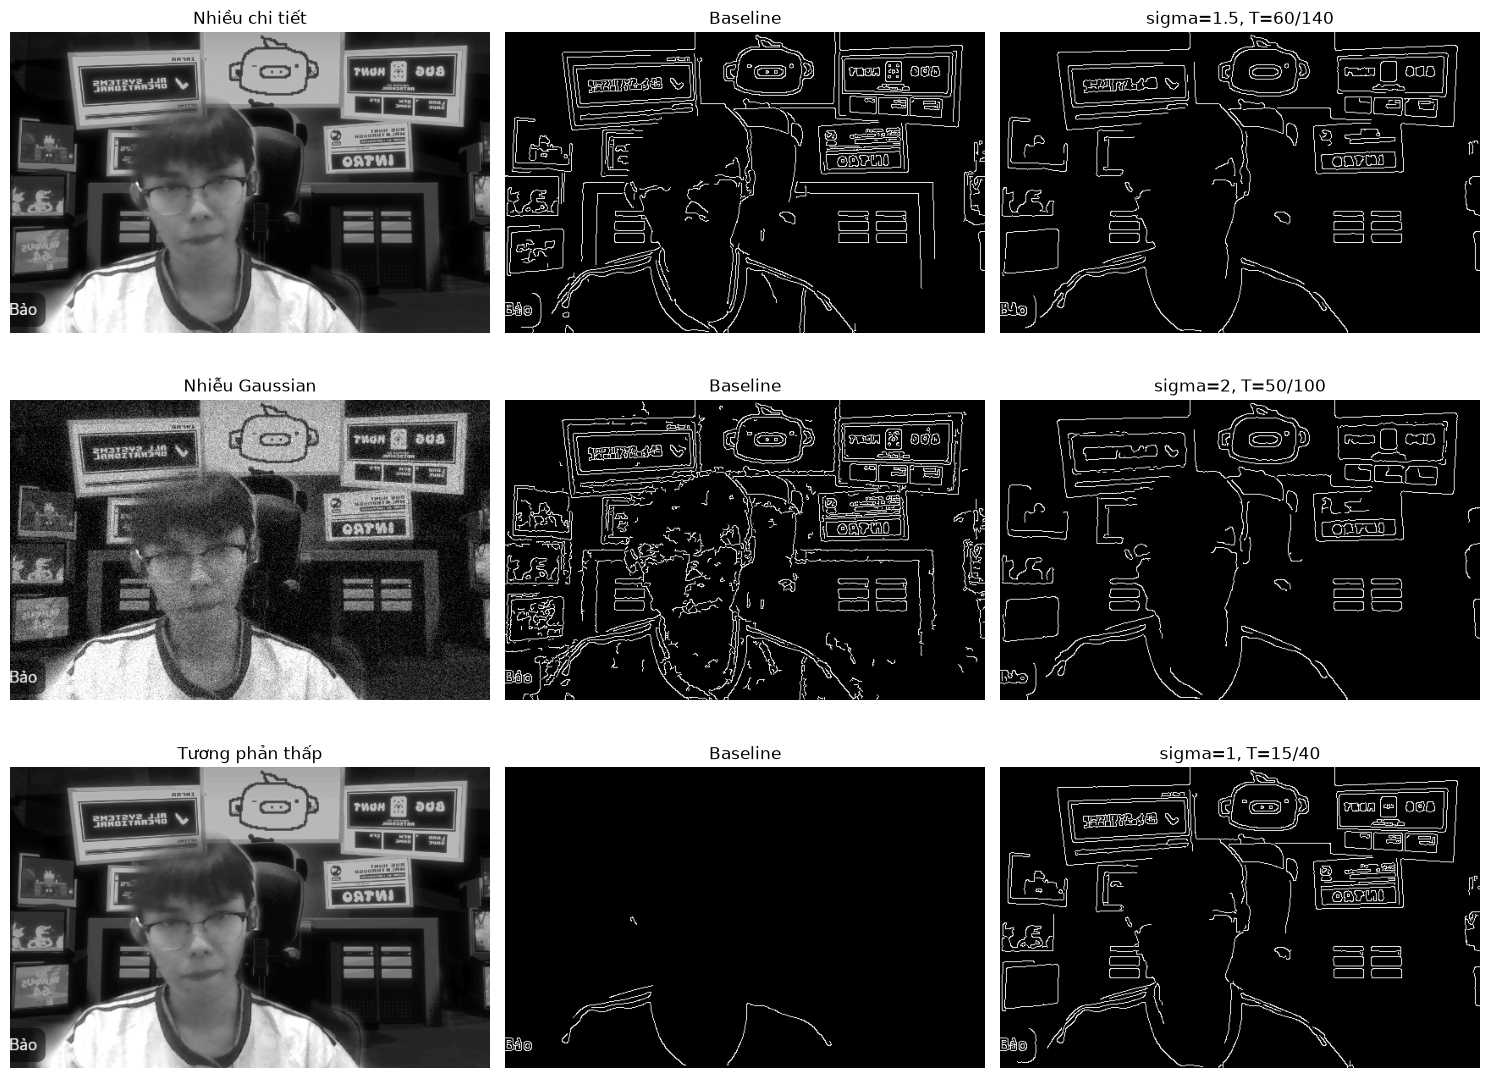

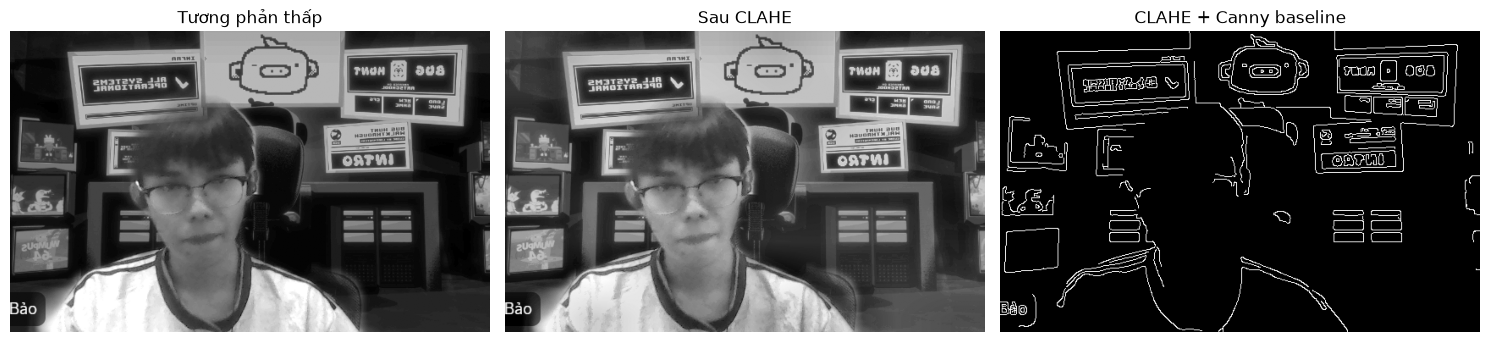

In [5]:
rng=np.random.default_rng(42)
noisy=np.clip(np.rint(gray.astype(float)+rng.normal(0,22,gray.shape)),0,255).astype(np.uint8)
low_contrast=np.rint(gray.astype(float)*0.25+90).astype(np.uint8)
variants=[('Nhiều chi tiết',gray),('Nhiễu Gaussian',noisy),('Tương phản thấp',low_contrast)]
items=[]
for name,im in variants:
    if name=='Nhiễu Gaussian': tuned=opencv_canny(im,2,50,100); label='sigma=2, T=50/100'
    elif name=='Tương phản thấp': tuned=opencv_canny(im,1,15,40); label='sigma=1, T=15/40'
    else: tuned=opencv_canny(im,1.5,60,140); label='sigma=1.5, T=60/140'
    items.extend([(name,im),('Baseline',opencv_canny(im)),(label,tuned)])
show(items,filename='04_image_types.png')
clahe=cv2.createCLAHE(clipLimit=2,tileGridSize=(8,8)).apply(low_contrast)
show([('Tương phản thấp',low_contrast),('Sau CLAHE',clahe),('CLAHE + Canny baseline',opencv_canny(clahe))],filename='05_clahe.png')

## 5. So sánh Sobel, Laplacian và Canny
Sobel tạo độ lớn gradient, thường cho cạnh dày. Laplacian là đạo hàm bậc hai, nhạy nhiễu; thí nghiệm dùng ngưỡng độ lớn (không phải zero crossing). Canny thêm NMS và liên kết cạnh.
Ảnh tổng hợp có biên tham chiếu vẽ từ tọa độ hình học, không dùng đầu ra Canny làm nhãn. Precision/recall/F1 cho phép sai lệch Euclid 2 pixel. Ghép nhiều-với-nhiều có thể ưu ái cạnh dày; kết quả chỉ dành cho bộ hình này. Thời gian là median 5 lần sau warm-up, gồm làm mượt, không gồm đọc/vẽ.

| method | median_ms | edge_pixels | precision | recall | f1 |
|---|---|---|---|---|---|
| OpenCV | 1.1820 | 1106 | 1.0000 | 1.0000 | 1.0000 |
| scikit-image | 7.0869 | 1097 | 1.0000 | 1.0000 | 1.0000 |
| Manual | 8.4062 | 1240 | 1.0000 | 1.0000 | 1.0000 |
| Sobel magnitude | 1.5056 | 4089 | 0.9587 | 1.0000 | 0.9789 |
| Laplacian magnitude | 0.8510 | 4706 | 0.8714 | 1.0000 | 0.9313 |


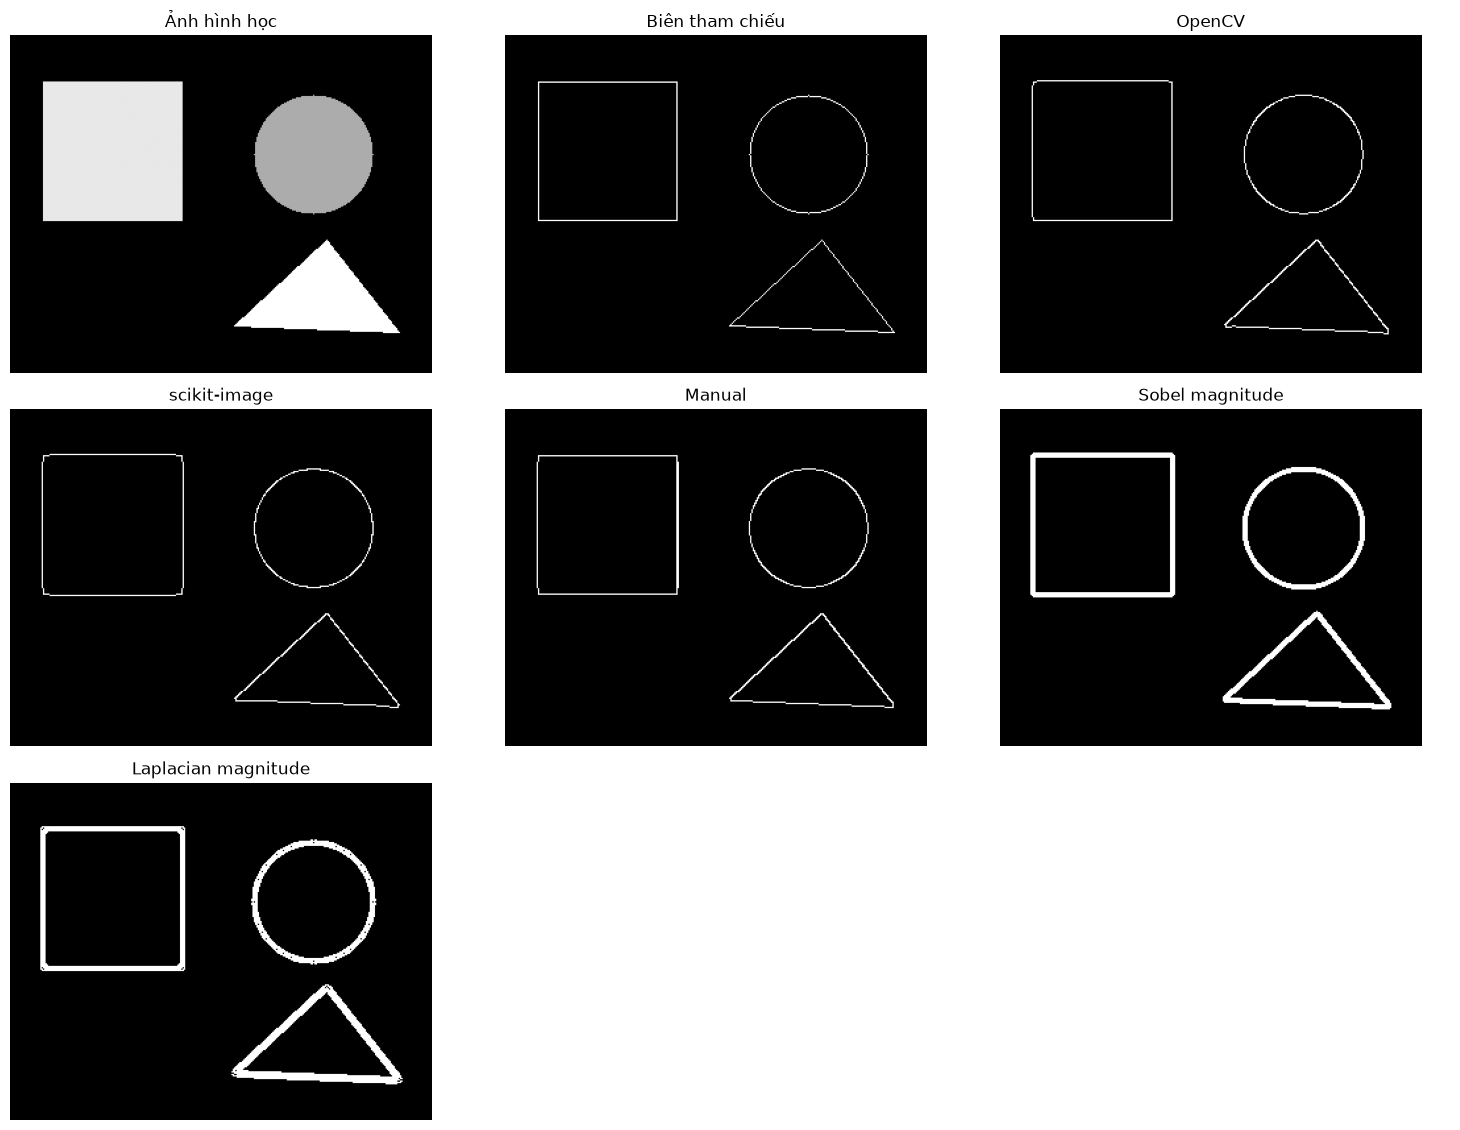

In [6]:
scene,truth=synthetic_scene()
records,predictions=benchmark(scene,truth)
columns=['method','median_ms','edge_pixels','precision','recall','f1']
def table(records,columns):
    text='| '+' | '.join(columns)+' |\n|'+'|'.join(['---']*len(columns))+'|\n'
    for record in records:
        text+='| '+' | '.join(f'{record[c]:.4f}' if isinstance(record[c],float) else str(record[c]) for c in columns)+' |\n'
    display(Markdown(text))
table(records,columns)
(OUT/'benchmark.json').write_text(json.dumps(records,indent=2),encoding='utf-8')
show([('Ảnh hình học',scene),('Biên tham chiếu',truth)]+list(predictions.items()),filename='06_benchmark.png')

### Khả năng xử lý nhiễu với tham chiếu cố định
Giữ hình học gốc, thêm nhiễu và chạy lại cùng baseline; không chọn ngưỡng theo kết quả này. Không dùng accuracy theo pixel vì nền chiếm đa số. Muốn so sánh tổng quát cần nhiều ảnh có annotation và tập validation/test độc lập; các ngưỡng Sobel/Laplacian ở đây chưa được tối ưu công bằng.

| method | median_ms | edge_pixels | precision | recall | f1 |
|---|---|---|---|---|---|
| OpenCV | 0.6323 | 1137 | 1.0000 | 1.0000 | 1.0000 |
| scikit-image | 7.1002 | 1099 | 1.0000 | 1.0000 | 1.0000 |
| Manual | 14.3964 | 1137 | 1.0000 | 1.0000 | 1.0000 |
| Sobel magnitude | 1.6628 | 4141 | 0.9534 | 1.0000 | 0.9761 |
| Laplacian magnitude | 0.8186 | 9124 | 0.4599 | 1.0000 | 0.6300 |


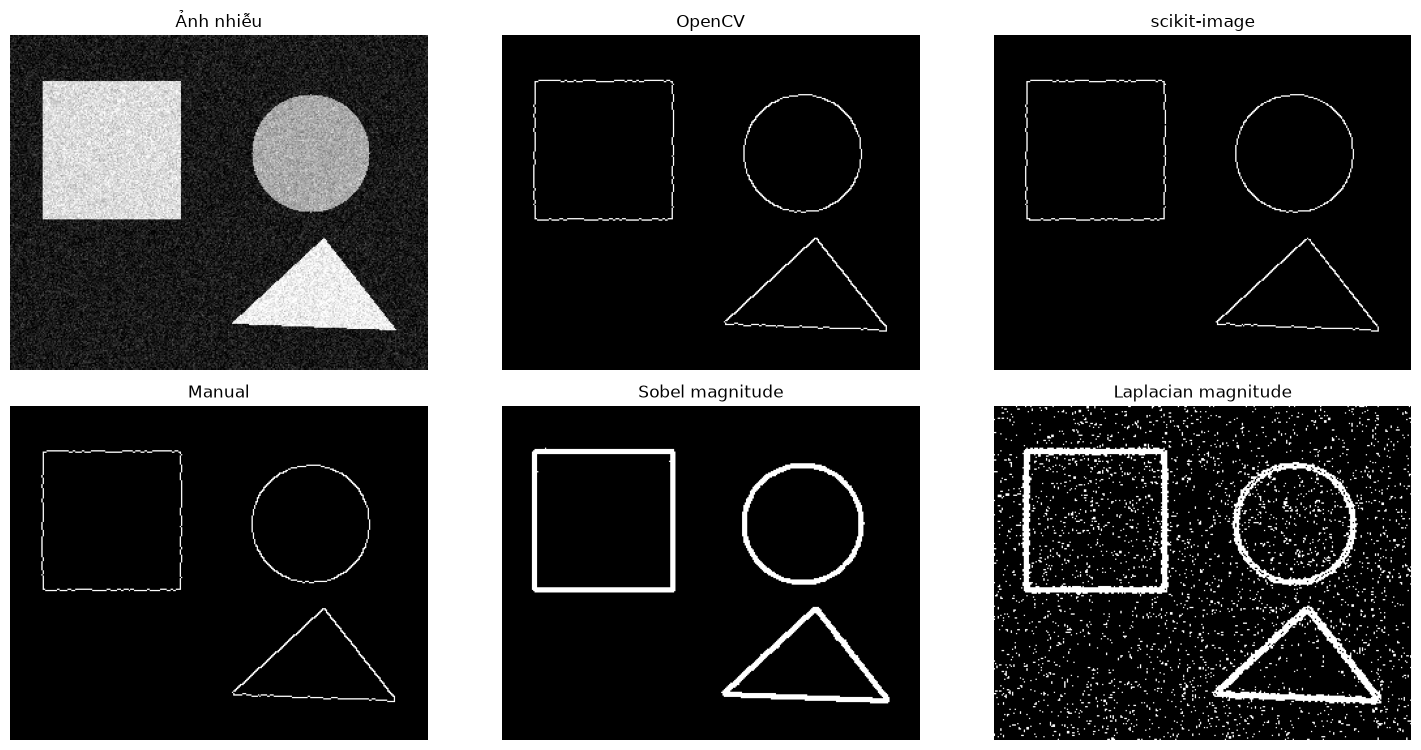

In [7]:
noisy_scene=np.clip(np.rint(scene.astype(float)+rng.normal(0,20,scene.shape)),0,255).astype(np.uint8)
noisy_records,noisy_predictions=benchmark(noisy_scene,truth)
table(noisy_records,columns)
(OUT/'benchmark_noisy.json').write_text(json.dumps(noisy_records,indent=2),encoding='utf-8')
show([('Ảnh nhiễu',noisy_scene)]+list(noisy_predictions.items()),filename='07_noise_benchmark.png')

## 6. Kết hợp phân đoạn vùng và nhận dạng hình dạng
Canny → morphology closing 3×3 → contour ngoài → tô vùng kín. Xấp xỉ đa giác: 3 đỉnh là tam giác, 4 đỉnh là tứ giác; circularity cao gợi ý hình tròn. Thử trên hình học rõ ràng. Cạnh hở/dính có thể làm kết quả sai; đây không phải nhận diện đối tượng tổng quát.

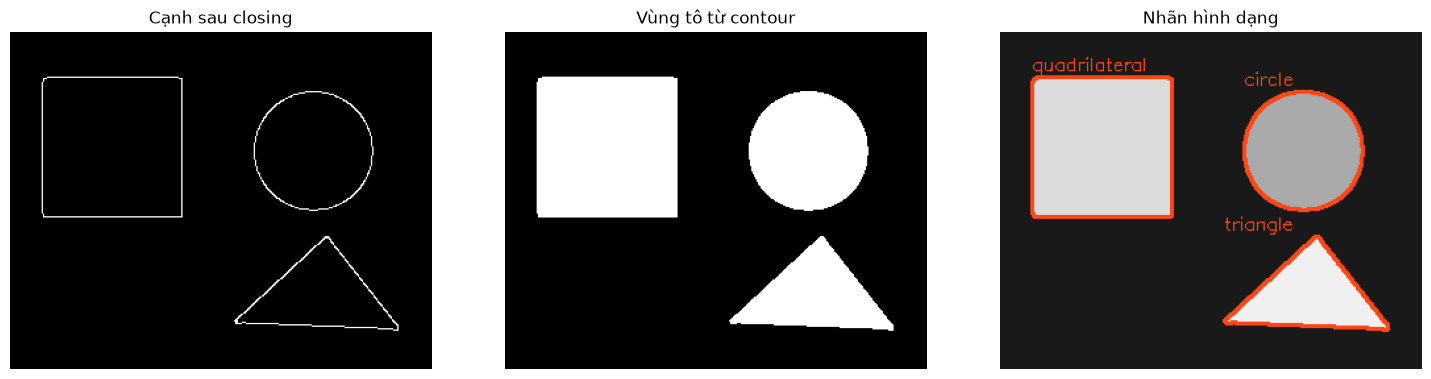

[{'shape': 'triangle', 'area': 4379.5, 'bbox': [170, 155, 125, 72]},
 {'shape': 'circle', 'area': 6380.0, 'bbox': [185, 45, 91, 91]},
 {'shape': 'quadrilateral', 'area': 11225.0, 'bbox': [24, 34, 107, 107]}]

351

In [8]:
closed,regions,overlay,objects=regions_and_shapes(scene)
show([('Cạnh sau closing',closed),('Vùng tô từ contour',regions),('Nhãn hình dạng',overlay)],filename='08_regions_shapes.png')
display(objects)
Image.fromarray(overlay).save(OUT/'shapes.png')
(OUT/'shapes.json').write_text(json.dumps(objects,indent=2),encoding='utf-8')

## 7. Canny trên ảnh màu
Grayscale có thể làm mất biên giữa hai màu có độ sáng gần nhau. Cách đơn giản: chạy Canny trên từng kênh RGB rồi OR. Cách này có thể tăng cạnh giả; gradient vector màu là hướng mở rộng khác.

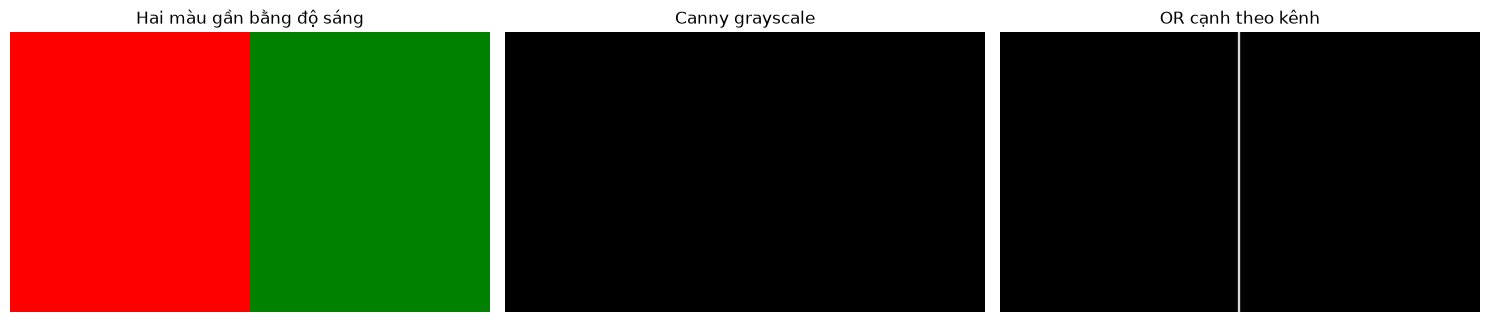

In [9]:
color=np.zeros((140,240,3),dtype=np.uint8)
color[:,:120]=[255,0,0]; color[:,120:]=[0,130,0]
color_gray=cv2.cvtColor(color,cv2.COLOR_RGB2GRAY)
channel_edges=np.logical_or.reduce([opencv_canny(color[:,:,i],1,50,100) for i in range(3)])
show([('Hai màu gần bằng độ sáng',color),('Canny grayscale',opencv_canny(color_gray)),('OR cạnh theo kênh',channel_edges)],filename='09_color_edges.png')

## 8. Canny cho video
Duyệt từng frame → grayscale → Canny → ghi MP4; giữ FPS và kích thước nguồn, giải phóng tài nguyên bằng finally. Có thể chạy CLI: `python canny_lab.py --video input.mp4 --output outputs/video`.
Cell sau tạo clip tổng hợp 12 frame và xử lý thật để kiểm chứng pipeline. Ngưỡng cố định có thể gây nhấp nháy khi ánh sáng thay đổi; cân nhắc ổn định thời gian và đo FPS end-to-end.

In [10]:
demo_path=OUT/'demo_input.mp4'
writer=cv2.VideoWriter(str(demo_path),cv2.VideoWriter_fourcc(*'mp4v'),12,(160,120))
if not writer.isOpened(): raise RuntimeError('Không mở được mp4v writer')
try:
    for i in range(12):
        frame=np.full((120,160,3),25,np.uint8)
        cv2.rectangle(frame,(15+i*3,30),(65+i*3,85),(220,220,220),-1)
        writer.write(frame)
finally: writer.release()
frames=process_video(demo_path,OUT/'demo_canny.mp4')
assert frames==12
print('Đã xử lý video:',frames,'frames; xem outputs/demo_canny.mp4')

Đã xử lý video: 12 frames; xem outputs/demo_canny.mp4


## 9. Nhận xét và câu hỏi mở rộng
- **Chất lượng cạnh:** đo precision/recall/F1 có dung sai, độ định vị, độ mảnh/liên tục và khả năng chống nhiễu; cần biên tham chiếu. Xem bảng thực tế ở trên thay vì giả định Canny luôn thắng.
- **Ưu điểm:** liên kết cạnh yếu với cạnh mạnh, làm mảnh cạnh và giảm nhiễu trước đạo hàm. **Nhược điểm:** phụ thuộc sigma/ngưỡng, có thể bỏ mất biên tương phản thấp, tăng chi phí so với đạo hàm đơn giản.
- **Cải thiện:** tiền xử lý phù hợp, CLAHE, ROI/resize, chọn ngưỡng trên validation; morphology có thể sửa cạnh hở nhưng cũng nối sai vùng.
- **Ứng dụng:** trích đường kẻ tài liệu, kiểm tra biên sản phẩm, tạo ứng viên đường thẳng/biên vật thể. Không tự hiểu ngữ nghĩa; chưa có bằng chứng để xếp lĩnh vực nào dùng phổ biến nhất.
- **Ảnh màu/video:** xem hai phần minh họa vừa chạy; cần cân nhắc mất biên màu, nhiễu và tính ổn định theo thời gian.

Bài tập tiếp: thử ảnh riêng, đọc các cặp tham số trong phần khảo sát, phân tích cạnh nào bị mất/tăng và lý do. Không dùng số pixel cạnh thay thế chất lượng.